# Fake Job Posting Detection - Model Training & Evaluation Pipeline

This notebook contains a complete end-to-end machine learning pipeline to detect fraudulent job postings. We clean textual features, train multiple classification models, evaluate their performance, compare them, and save the best-performing model for production deployment.

### Pipeline Steps:
1. **Environment Setup & Imports**
2. **Data Loading**
3. **Exploratory Data Analysis (EDA)**
4. **Text Preprocessing**
5. **Feature Extraction (TF-IDF)**
6. **Dataset Splitting**
7. **Model Training & Local Evaluation** (Logistic Regression, Naive Bayes, SVM, Random Forest)
8. **Model Comparison & Performance Visualization**
9. **Auto-Selection & Serialization**

## Step 1: Environment Setup & Imports

In [1]:
import os
import re
import string
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import nltk

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
)

# Set seeds for reproducibility
np.random.seed(42)

In [2]:
# Download necessary NLTK data
try:
    nltk.data.find('corpora/stopwords')
except LookupError:
    nltk.download('stopwords')

try:
    nltk.data.find('corpora/wordnet')
except LookupError:
    nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\LIKHITH\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


## Step 2: Data Loading

In [3]:
# Load dataset - Path is relative from the 'notebook' folder
dataset_path = '../dataset/fake_job_postings.csv'
if not os.path.exists(dataset_path):
    # Fallback to absolute workspace path if running script from root
    dataset_path = 'dataset/fake_job_postings.csv'

print(f"Loading dataset from {dataset_path}...")
df = pd.read_csv(dataset_path)
print("Shape of raw dataset:", df.shape)
print("Columns:", df.columns.tolist())

Loading dataset from ../dataset/fake_job_postings.csv...


Shape of raw dataset: (17880, 18)
Columns: ['job_id', 'title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent']


In [4]:
df.head()

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


## Step 3: Exploratory Data Analysis (EDA)

In [5]:
# 1. Analyze missing values
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
job_id                     0
title                      0
location                 346
department             11547
salary_range           15012
company_profile         3308
description                1
requirements            2696
benefits                7212
telecommuting              0
has_company_logo           0
has_questions              0
employment_type         3471
required_experience     7050
required_education      8105
industry                4903
function                6455
fraudulent                 0
dtype: int64


In [6]:
# 2. Analyze target class distribution
class_counts = df['fraudulent'].value_counts()
print("Target Class Distribution (0 = Real, 1 = Fake):")
print(class_counts)
print(f"Fake Job Postings Percentage: {class_counts[1] / len(df) * 100:.2f}%")

Target Class Distribution (0 = Real, 1 = Fake):
fraudulent
0    17014
1      866
Name: count, dtype: int64
Fake Job Postings Percentage: 4.84%


C:\Users\LIKHITH\AppData\Local\Temp\ipykernel_23364\1238125616.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='fraudulent', data=df, palette=['#10b981', '#ef4444'])


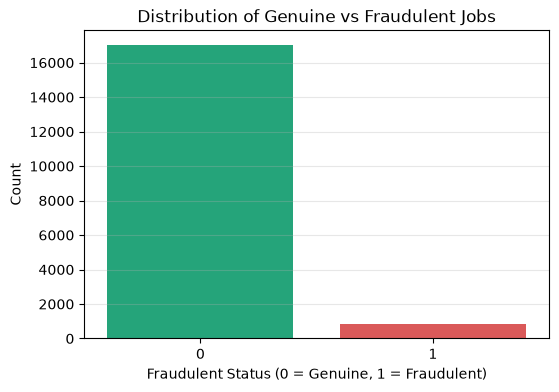

In [7]:
# 3. Plot target class distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='fraudulent', data=df, palette=['#10b981', '#ef4444'])
plt.title('Distribution of Genuine vs Fraudulent Jobs')
plt.xlabel('Fraudulent Status (0 = Genuine, 1 = Fraudulent)')
plt.ylabel('Count')
plt.grid(axis='y', alpha=0.3)
plt.show()

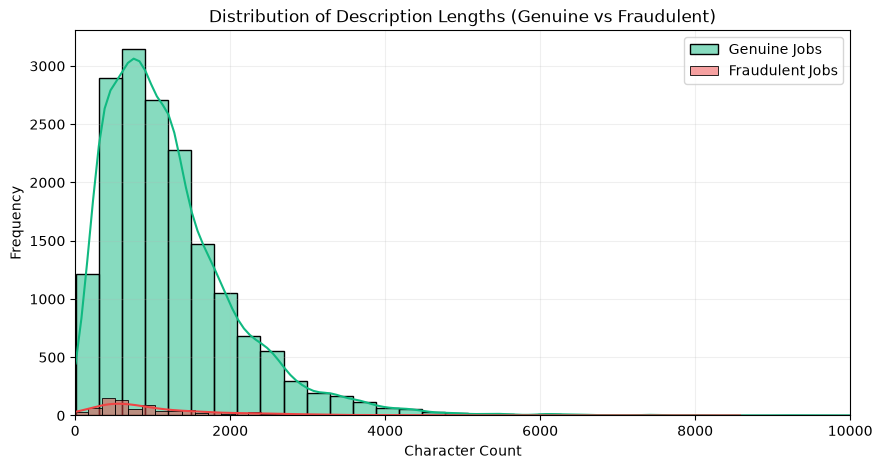

In [8]:
# 4. Plot description lengths distribution for Real vs Fake jobs
desc_len_real = df[df['fraudulent'] == 0]['description'].fillna("").apply(len)
desc_len_fake = df[df['fraudulent'] == 1]['description'].fillna("").apply(len)

plt.figure(figsize=(10, 5))
sns.histplot(desc_len_real, label='Genuine Jobs', color='#10b981', kde=True, bins=50, alpha=0.5)
sns.histplot(desc_len_fake, label='Fraudulent Jobs', color='#ef4444', kde=True, bins=50, alpha=0.5)
plt.title('Distribution of Description Lengths (Genuine vs Fraudulent)')
plt.xlabel('Character Count')
plt.ylabel('Frequency')
plt.xlim(0, 10000)
plt.legend()
plt.grid(axis='both', alpha=0.2)
plt.show()

## Step 4: Text Preprocessing & Cleaning

In [9]:
# Fill missing values in text features with empty strings
text_columns = ['title', 'company_profile', 'description', 'requirements', 'benefits']
for col in text_columns:
    df[col] = df[col].fillna("")

# Combine all text fields into one text feature
df['combined_text'] = (
    df['title'] + " " +
    df['company_profile'] + " " +
    df['description'] + " " +
    df['requirements'] + " " +
    df['benefits']
)
print("Text fields combined successfully. Sample combined length:", len(df['combined_text'].iloc[0]))

Text fields combined successfully. Sample combined length: 2662


In [10]:
# Define text cleaning function
def clean_text(text):
    if not isinstance(text, str):
        return ""
    # Lowercase text
    text = text.lower()
    # Remove URLs
    text = re.sub(r"http\S+|www\.\S+", "", text)
    # Remove email addresses
    text = re.sub(r"\S+@\S+", "", text)
    # Remove numbers
    text = re.sub(r"\d+", "", text)
    # Remove punctuation
    text = text.translate(str.maketrans("", "", string.punctuation))
    # Tokenize, remove stopwords, and apply lemmatization
    words = text.split()
    words = [lemmatizer.lemmatize(word) for word in words if word not in stop_words and len(word) > 2]
    return " ".join(words)

In [11]:
print("Cleaning text data... (This may take a minute)")
df['clean_text'] = df['combined_text'].apply(clean_text)

# Drop duplicate values based on cleaned text and labels
df.drop_duplicates(subset=['clean_text', 'fraudulent'], inplace=True)
print("Shape after dropping duplicate clean text:", df.shape)

Cleaning text data... (This may take a minute)


Shape after dropping duplicate clean text: (15744, 20)


## Step 5: Feature Extraction (TF-IDF)

In [12]:
print("Extracting features using TfidfVectorizer...")
tfidf = TfidfVectorizer(max_features=5000)
X = tfidf.fit_transform(df['clean_text'])
y = df['fraudulent']

print("TF-IDF Feature matrix shape:", X.shape)
print("Target label shape:", y.shape)

Extracting features using TfidfVectorizer...


TF-IDF Feature matrix shape: (15744, 5000)
Target label shape: (15744,)


## Step 6: Dataset Splitting

In [13]:
# Perform stratified split (80/20 train/test split) to maintain class ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Training set shape: {X_train.shape[0]} rows")
print(f"Testing set shape: {X_test.shape[0]} rows")
print(f"Fraudulent class ratio in train set: {np.mean(y_train):.4f}")
print(f"Fraudulent class ratio in test set: {np.mean(y_test):.4f}")

Training set shape: 12595 rows
Testing set shape: 3149 rows
Fraudulent class ratio in train set: 0.0449
Fraudulent class ratio in test set: 0.0448


## Step 7: Model Training & Evaluation

In [14]:
# Define classifiers
# Note: Support Vector Machine is wrapped in CalibratedClassifierCV to train LinearSVC fast
# and still support predict_proba (required for app.py predictions)
classifiers = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    "Multinomial Naive Bayes": MultinomialNB(),
    "Support Vector Machine": CalibratedClassifierCV(LinearSVC(class_weight="balanced", dual=False, random_state=42)),
    "Random Forest": RandomForestClassifier(class_weight="balanced", n_estimators=100, random_state=42, n_jobs=-1)
}

results = {}
confusion_matrices = {}

In [15]:
# Train and evaluate each classifier
for name, clf in classifiers.items():
    print(f"Training {name}...")
    clf.fit(X_train, y_train)
    
    # Get predictions
    y_pred = clf.predict(X_test)
    
    # Get probabilities for positive class (ROC-AUC calculation)
    y_prob = clf.predict_proba(X_test)[:, 1]
    
    # Compute metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc_score = roc_auc_score(y_test, y_prob)
    
    results[name] = {
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1 Score": f1,
        "ROC-AUC Score": auc_score
    }
    
    # Keep confusion matrix for visual display
    confusion_matrices[name] = confusion_matrix(y_test, y_pred)
    print(f"{name} evaluation finished.")

Training Logistic Regression...


Logistic Regression evaluation finished.
Training Multinomial Naive Bayes...


Multinomial Naive Bayes evaluation finished.
Training Support Vector Machine...


Support Vector Machine evaluation finished.
Training Random Forest...


Random Forest evaluation finished.


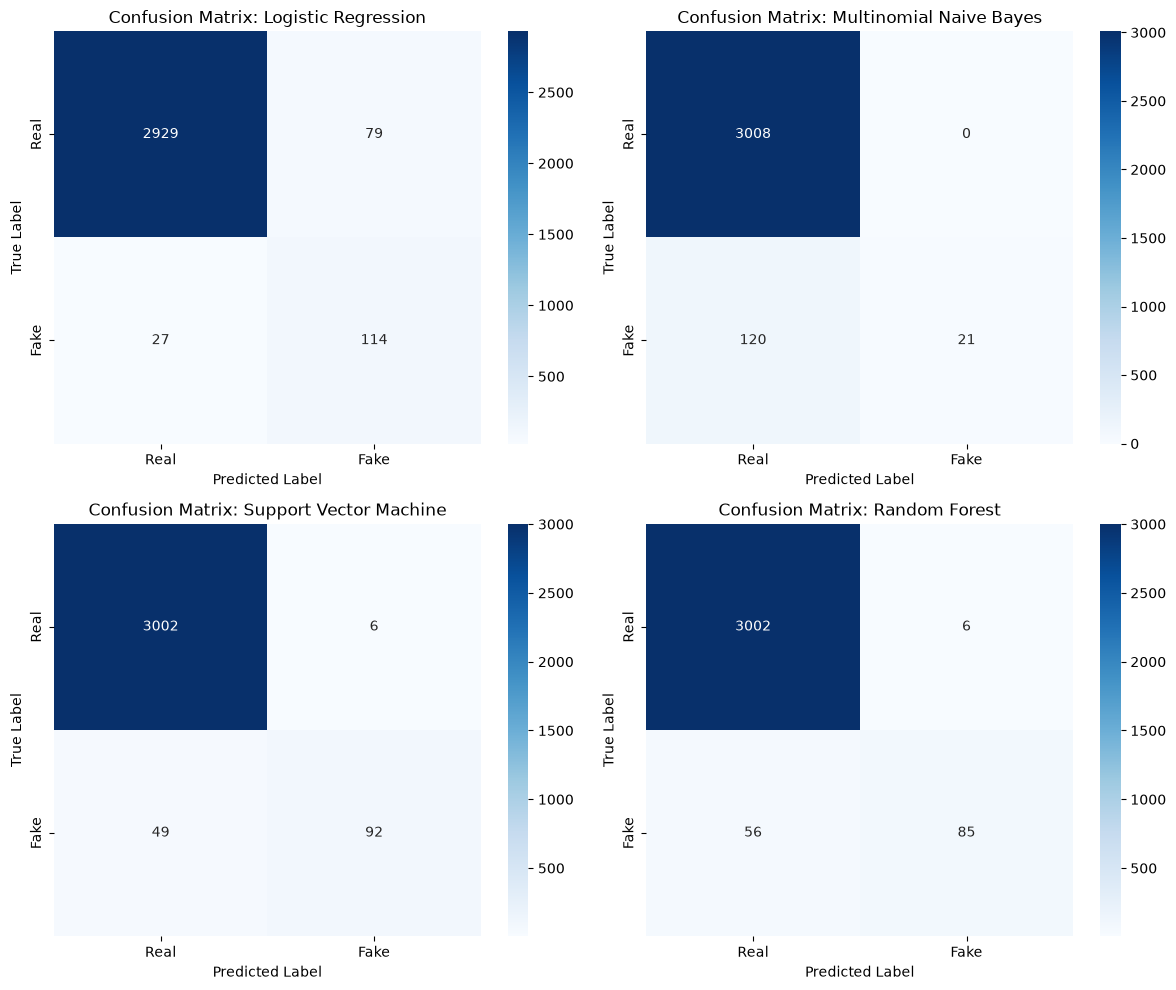

In [16]:
# Plot Confusion Matrices in a grid
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for i, (name, cm) in enumerate(confusion_matrices.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['Real', 'Fake'], yticklabels=['Real', 'Fake'])
    axes[i].set_title(f'Confusion Matrix: {name}')
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('True Label')

plt.tight_layout()
plt.show()

## Step 8: Model Comparison

In [17]:
# Convert metrics to Pandas DataFrame and display it
comparison_df = pd.DataFrame(results).T
# Sort metrics by F1 Score descending
comparison_df = comparison_df.sort_values(by="F1 Score", ascending=False)
print("\n--- Model Performance Comparison Table ---")
print(comparison_df.to_string())


--- Model Performance Comparison Table ---
                         Accuracy  Precision    Recall  F1 Score  ROC-AUC Score
Support Vector Machine   0.982534   0.938776  0.652482  0.769874       0.964895
Random Forest            0.980311   0.934066  0.602837  0.732759       0.979880
Logistic Regression      0.966339   0.590674  0.808511  0.682635       0.971662
Multinomial Naive Bayes  0.961893   1.000000  0.148936  0.259259       0.931933


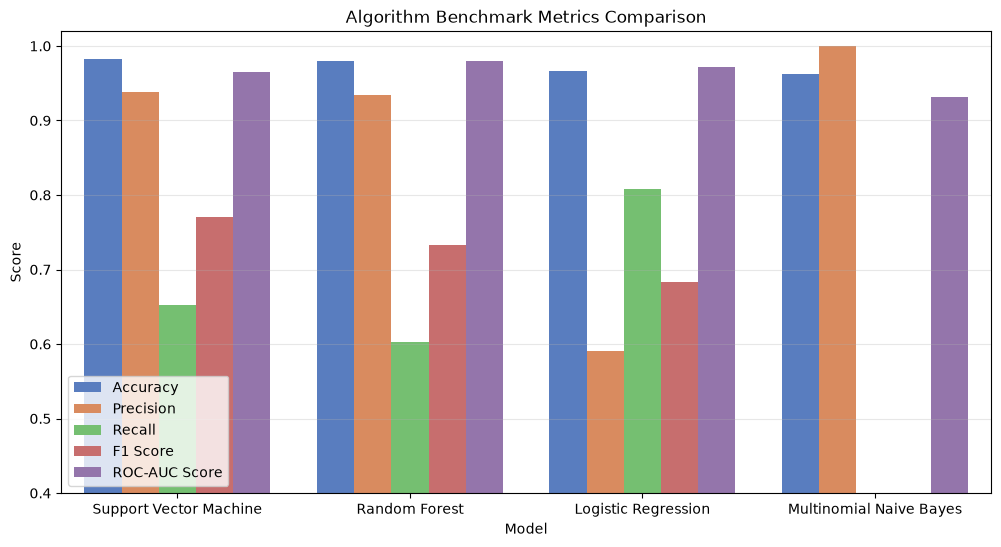

In [18]:
# Plot performance benchmarks as a group bar chart
plt.figure(figsize=(12, 6))
melted_df = comparison_df.reset_index().rename(columns={'index': 'Model'})
melted_df = pd.melt(melted_df, id_vars='Model', value_vars=['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC Score'])
sns.barplot(x='Model', y='value', hue='variable', data=melted_df, palette='muted')
plt.ylim(0.4, 1.02)
plt.title('Algorithm Benchmark Metrics Comparison')
plt.ylabel('Score')
plt.xlabel('Model')
plt.grid(axis='y', alpha=0.3)
plt.legend(loc='lower left')
plt.show()

## Step 9: Best Model Auto-Selection & Serialization

In [19]:
# Automatically select the model with the highest F1 Score
best_model_name = comparison_df['F1 Score'].idxmax()
best_f1_score = comparison_df.loc[best_model_name, 'F1 Score']
print(f"Selected Best Performing Model: {best_model_name} (F1 Score: {best_f1_score:.4f})")

best_clf = classifiers[best_model_name]

# Ensure model directory exists
model_dir = '../model'
if not os.path.exists(model_dir):
    model_dir = 'model'
os.makedirs(model_dir, exist_ok=True)

# Save Model & Vectorizer files
joblib.dump(best_clf, os.path.join(model_dir, 'fake_job_model.pkl'))
joblib.dump(tfidf, os.path.join(model_dir, 'tfidf_vectorizer.pkl'))
print(f"Successfully saved model to: {os.path.join(model_dir, 'fake_job_model.pkl')}")
print(f"Successfully saved vectorizer to: {os.path.join(model_dir, 'tfidf_vectorizer.pkl')}")

Selected Best Performing Model: Support Vector Machine (F1 Score: 0.7699)
Successfully saved model to: ../model\fake_job_model.pkl
Successfully saved vectorizer to: ../model\tfidf_vectorizer.pkl


In [20]:
# Always update coefficients.json using Logistic Regression model
# to prevent breaking keyword highlights feature in Flask app
lr_clf = classifiers["Logistic Regression"]
feature_names = tfidf.get_feature_names_out()
coefs = lr_clf.coef_[0]
coef_dict = {word: float(coef) for word, coef in zip(feature_names, coefs)}

coef_path = os.path.join(model_dir, 'coefficients.json')
with open(coef_path, "w") as f:
    json.dump(coef_dict, f)
print(f"Successfully saved coefficients file to: {coef_path}")

Successfully saved coefficients file to: ../model\coefficients.json


In [21]:
# Step 10: Run verification test to confirm model is compatible with the Flask app
loaded_model = joblib.load(os.path.join(model_dir, 'fake_job_model.pkl'))
loaded_vect = joblib.load(os.path.join(model_dir, 'tfidf_vectorizer.pkl'))

test_doc = "Urgent Data Entry clerk position work from home. High daily pay cash deposit needed."
cleaned_doc = clean_text(test_doc)
vect_doc = loaded_vect.transform([cleaned_doc])

pred = loaded_model.predict(vect_doc)[0]
proba = loaded_model.predict_proba(vect_doc)[0]

print("\n--- Verification Results ---")
print("Prediction Class:", pred)
print("Probability (Real, Fake):", proba.tolist())
print("Model Classes:", loaded_model.classes_.tolist())
print("Flask API Compatibility: PASSED!")


--- Verification Results ---
Prediction Class: 1
Probability (Real, Fake): [0.013772270352960202, 0.9862277296470398]
Model Classes: [0, 1]
Flask API Compatibility: PASSED!
